![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Hypothesis Testing
*Data Science & Machine Learning - Week 4, Day 2*

**How to use this notebook**

Start with the slides **1. Hypothesis Testing** before section 2, **5. AB_testing_ironhack** before section 5, and **3. Goodness of Fit** before section 7.

The live lesson runs from section 1 to section 7. The Appendix and the Solutions are for practice.

The notebook reads from the `Data/` folder, so download or clone the whole `s-405` folder, not just this file.

## Table of Contents

- [1. Central Limit Theorem](#1.-Central-Limit-Theorem)
- [2. The hypothesis-testing recipe](#2.-The-hypothesis-testing-recipe)
- [3. One-sample t-test](#3.-One-sample-t-test)
- [4. Paired samples t-test](#4.-Paired-samples-t-test)
- [5. Independent samples t-test: an A/B test](#5.-Independent-samples-t-test:-an-A/B-test)
- [6. One-way ANOVA](#6.-One-way-ANOVA)
- [7. Chi-square tests on counts](#7.-Chi-square-tests-on-counts)
    - [7.1 Goodness of fit: soft drinks](#7.1-Goodness-of-fit:-soft-drinks)
    - [7.2 Independence: car manufacturers](#7.2-Independence:-car-manufacturers)
- [Appendix](#Appendix)
    - [A.1 Why sample size and spread matter](#A.1-Why-sample-size-and-spread-matter)
    - [A.2 Business challenge: customer spending and the Central Limit Theorem](#A.2-Business-challenge:-customer-spending-and-the-Central-Limit-Theorem)
- [Solutions](#Solutions)

## 1. Central Limit Theorem

The Central Limit Theorem (CLT) is a fundamental concept in statistics, and it plays a crucial role in explaining why the normal distribution is so pervasive in various fields.[Central Limit Theorem](https://www.youtube.com/watch?v=b5xQmk9veZ4&ab_channel=365DataScience)

#### The Central Limit Theorem Explained

The Central Limit Theorem states that:

> If you take the mean of $( n )$ random samples from any arbitrary distribution with a well-defined standard deviation $( \sigma )$ and mean $( \mu )$, as $( n )$ gets larger, the distribution of the sample mean will converge to a Gaussian (normal) distribution with mean $( \mu $) and standard deviation $( \frac{\sigma}{\sqrt{n}} )$.

#### Key Aspects of the CLT

- **Applicability to Any Distribution**: The CLT is remarkable because it applies to any distribution, no matter its shape, as long as the distribution has a well-defined mean and standard deviation.
- **Sample Size and Normal Distribution**: As the sample size increases, the distribution of the sample means tends toward a normal distribution, regardless of the shape of the original data distribution.
- **Mean and Standard Deviation of the Sample Means**: The mean of these sample means will equal the population mean (\( \mu \)), and their standard deviation (also called the standard error) will be \( \frac{\sigma}{\sqrt{n}} \).

#### Why is the CLT Significant?

- **Ubiquity of the Normal Distribution**: The CLT helps to explain why normal distributions are commonly observed in real-world data—even when the underlying data does not follow a normal distribution.
- **Foundation for Statistical Methods**: This theorem underlies many statistical methods, such as hypothesis testing and confidence intervals. It allows for inferences about population parameters even when the distribution of the population is unknown.
- **Practical Implications**: In practical terms, the CLT means that average measurements from random samples (like the average height from a sample of people) will tend to form a normal distribution, even if individual measurements themselves do not.

#### Applications and Implications

The CLT has widespread applications across various domains, from natural and social sciences to engineering and economics. It allows researchers and practitioners to use the powerful tools of normal distribution, even in situations where the data does not initially appear to fit this model.

In essence, the Central Limit Theorem provides a bridge between the theory of probability and the practice of statistics, justifying the use of the normal distribution as a model in many practical situations.


#### Example Central Limit Theorem in Business: Daily Sales Analysis

In this exercise, we'll explore the Central Limit Theorem (CLT) using a practical business example. We will simulate a common scenario in retail - daily sales. Understanding the CLT can be crucial in business for making predictions and understanding data trends.

#### Scenario: Retail Store Daily Sales

In a retail environment, daily sales can vary significantly and might not follow a normal distribution. However, by applying the CLT, we can understand how the average sales over time behave, which is critical for inventory management, staffing, and financial forecasting.

#### Objective

The aim is to simulate daily sales data, compute sample means over different sample sizes, and observe how these sample means form a distribution. According to the CLT, as the sample size increases, the distribution of the sample means should approximate a normal distribution, regardless of the shape of the original sales data distribution.

#### Python Simulation

The provided Python code carries out the following steps:
1. Generates random daily sales figures assuming a uniform distribution (non-normal).
2. Calculates sample means for different sample sizes.
3. Plots the distribution of these sample means.
4. Fits a normal distribution over the sample means to visualize the CLT.

This practical example will demonstrate the power of the CLT in a business context, showcasing its relevance and application in everyday data analysis tasks in the retail industry.


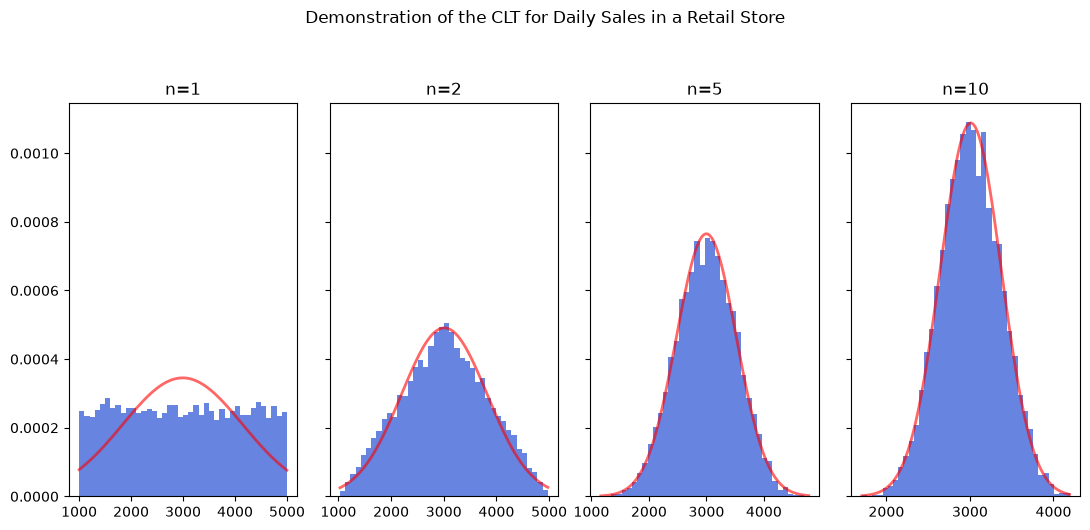

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Setting up a demonstration of the Central Limit Theorem (CLT) using daily sales data
fig, ax = plt.subplots(1, 4, sharey=True, squeeze=True, figsize=(11, 5))

# Assume sales amounts are uniformly distributed between $1000 and $5000
lower_bound, upper_bound = 1000, 5000
sample_sizes = [1, 2, 5, 10]  # Different sample sizes to demonstrate the CLT

for i, n in enumerate(sample_sizes):
    # Generating random daily sales data for 'n' days
    daily_sales = np.random.uniform(lower_bound, upper_bound, (10000, n))

    # Calculating the mean of daily sales for each of the 10,000 samples
    sample_means = np.mean(daily_sales, axis=1)

    # Plotting the histogram of the sample means
    ax[i].hist(sample_means, bins=40, density=True, color=[0, 0.2, .8, .6])
    ax[i].set_title(f'n={n}')

    # Fitting a normal distribution to the sample means
    mean, std = np.mean(sample_means), np.std(sample_means, ddof=1)
    x = np.linspace(min(sample_means), max(sample_means), 100)
    normal_pdf = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-(x - mean) ** 2 / (2 * std ** 2))
    
    # Plotting the fitted normal distribution over the histogram
    ax[i].plot(x, normal_pdf, color=[1, 0, 0, .6], linewidth=2)

plt.suptitle('Demonstration of the CLT for Daily Sales in a Retail Store', y=1.05)
plt.tight_layout()
plt.show()


**The Central Limit Theorem explains the importance of normal distributions in the real world. Many features and properties of the living beings depend on genetic and environmental factors which effect usually is additive.** The measured features are sum of manny small effects that not necessarily follow the normal distributions, but their sum does follow according to the Central Limit Theorem.



## 2. The hypothesis-testing recipe

Every test in this lesson follows the same five steps:

1. State the **null hypothesis** H₀ (no effect, no difference) and the **alternative** H₁ (what you suspect).
2. Pick a **significance level** α before looking at the data, usually 0.05.
3. Choose the test that matches the question and the data (table below).
4. Compute the **test statistic** and its **p-value**.
5. If p < α, **reject H₀**. Otherwise you **fail to reject** it, which is not the same as proving it true.

The p-value is the probability of seeing data at least this extreme *if H₀ were true*. A small p-value means the data is hard to explain by chance alone.

| Question | Test | `scipy.stats` |
| --- | --- | --- |
| Is one mean different from a known value? | one-sample t-test | `ttest_1samp(sample, popmean)` |
| Same subjects, before vs after? | paired t-test | `ttest_rel(before, after)` |
| Two independent groups (an A/B test)? | independent t-test (Welch) | `ttest_ind(a, b, equal_var=False)` |
| Three or more groups? | one-way ANOVA | `f_oneway(g1, g2, g3, ...)` |
| Do observed counts match expected counts? | chi-square goodness of fit | `chisquare(f_obs, f_exp)` |
| Are two categorical variables independent? | chi-square independence | `chi2_contingency(table)` |

By default H₁ is "different" (two-sided). When H₁ has a direction, pass `alternative='less'` or `alternative='greater'`.

## 3. One-sample t-test

Is the average 3rd-class fare on the Titanic different from 17 USD? We only look at a sample of 30 passengers, as you would in practice.

H₀: μ = 17 &nbsp;&nbsp; vs &nbsp;&nbsp; H₁: μ ≠ 17

In [2]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv('Data/titanic_train.csv')
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Sample 30 passengers from 3rd class
c3_sample = data[data['Pclass'] == 3]['Fare'].sample(30, random_state=42)
c3_sample.mean()

np.float64(18.353333333333335)

In [5]:
# Test statistic and p-value
st.ttest_1samp(c3_sample, 17)

TtestResult(statistic=np.float64(0.4108853618174746), pvalue=np.float64(0.6841770101731536), df=np.int64(29))

With this sample the p-value is about 0.68, well above 0.05, so we **fail to reject** H₀.

But we happen to have every 3rd-class passenger, so we can check:

In [6]:
data[data['Pclass'] == 3]['Fare'].mean()

np.float64(13.675550101832993)

The true average is about 13.7 USD, so H₀ is false and the test missed it. That is a **type II error**. Fares are very skewed and 30 passengers is a small sample: only about 4 in 10 random samples of 30 would catch this difference. Compare decisions around the class, then take a bigger sample:

In [7]:
c3_sample_100 = data[data['Pclass'] == 3]['Fare'].sample(100, random_state=42)
st.ttest_1samp(c3_sample_100, 17)

TtestResult(statistic=np.float64(-2.6618462612995337), pvalue=np.float64(0.009069539925334574), df=np.int64(99))

Now p is below 0.05 and we reject H₀: the average 3rd-class fare is not 17 USD.

If H₁ has a direction — the fare is *lower* than 17 — the test is one-tailed, and its p-value is half the two-sided one:

H₀: μ ≥ 17 &nbsp;&nbsp; vs &nbsp;&nbsp; H₁: μ < 17

In [8]:
st.ttest_1samp(c3_sample_100, 17, alternative='less')

TtestResult(statistic=np.float64(-2.6618462612995337), pvalue=np.float64(0.004534769962667287), df=np.int64(99))

**Exercise:** are 1st-class fares different from 85 USD? Sample 30 1st-class passengers and use a 5% significance level. The answer is in the Solutions at the end.

In [9]:
# H0: mu = 85   vs   H1: mu != 85

## 4. Paired samples t-test

The same 100 patients have their blood pressure measured before and after a treatment. Each "after" belongs to a "before", so the two samples are **dependent**: the paired test works on the difference for each patient.

In [10]:
blood_pressure = pd.read_csv('Data/blood_pressure.csv')
blood_pressure.head()

,before,after
0,136.713072,92.432965
1,134.735618,105.022643
2,127.529115,82.242766
3,144.527126,93.607172
4,124.214720,103.212223


In [11]:
# H0: mu_before = mu_after   vs   H1: mu_before != mu_after
st.ttest_rel(blood_pressure['before'], blood_pressure['after'])

TtestResult(statistic=np.float64(27.29184176756024), pvalue=np.float64(7.303035069607892e-48), df=np.int64(99))

In [12]:
# H0: mu_before <= mu_after   vs   H1: mu_before > mu_after  (the treatment lowers blood pressure)
st.ttest_rel(blood_pressure['before'], blood_pressure['after'], alternative='greater')

TtestResult(statistic=np.float64(27.29184176756024), pvalue=np.float64(3.651517534803946e-48), df=np.int64(99))

## 5. Independent samples t-test: an A/B test

An **A/B test** splits users at random between two versions — A is the current website interface, B the new one — and compares an outcome, here the transaction value. The two groups are different people, so the samples are **independent**.

`equal_var=False` runs Welch's version of the test, which does not assume the two groups have the same spread. It is the safer default.

H₀: μ_A = μ_B &nbsp;&nbsp; vs &nbsp;&nbsp; H₁: μ_A ≠ μ_B

In [13]:
ab_test = pd.read_csv('Data/ab_test.csv')
ab_test.head()

,a,b
0,0.27,13.61
1,6.08,21.53
2,13.74,9.23
3,9.70,5.36
4,7.00,12.90


In [14]:
st.ttest_ind(ab_test['a'], ab_test['b'], equal_var=False)

TtestResult(statistic=np.float64(-2.637533181209767), pvalue=np.float64(0.009776243024828829), df=np.float64(93.79317907867807))

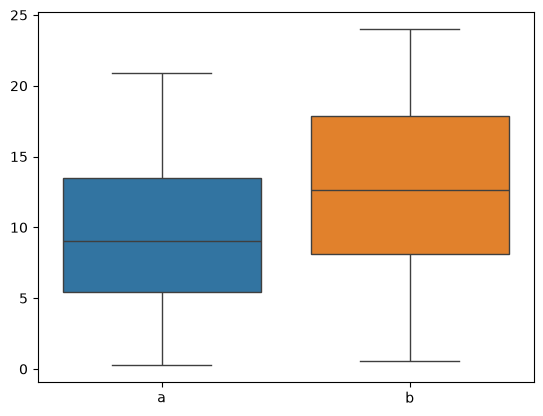

In [15]:
sns.boxplot(data=ab_test)
plt.show()

## 6. One-way ANOVA

Comparing interest rates in six cities two at a time would take 15 t-tests, and at 5% each the chance of a false positive piles up. ANOVA asks one question: are all the means equal? A small p-value says **at least one** city differs, not which one.

H₀: μ₁ = μ₂ = … = μ₆ &nbsp;&nbsp; vs &nbsp;&nbsp; H₁: at least one mean differs

In [16]:
interest_r = pd.read_csv('Data/rate_by_city.csv')
interest_r.head()

,Rate,City
0,13.75,1
1,13.75,1
2,13.50,1
3,13.50,1
4,13.00,1


In [17]:
interest_r['city_count'] = interest_r.groupby('City').cumcount() ##is the new index

interest_r_pivot = interest_r.pivot(index='city_count', columns='City', values='Rate')
interest_r_pivot.columns = ['City_'+str(x) for x in interest_r_pivot.columns.values]
interest_r_pivot

,City_1,City_2,City_3,City_4,City_5,City_6
city_count,,,,,,
0,13.75,14.25,14.00,15.00,14.50,13.50
1,13.75,13.00,14.00,14.00,14.00,12.25
2,13.50,12.75,13.51,13.75,14.00,12.25
3,13.50,12.50,13.50,13.59,13.90,12.00
4,13.00,12.50,13.50,13.25,13.75,12.00
5,13.00,12.40,13.25,12.97,13.25,12.00
6,13.00,12.30,13.00,12.50,13.00,12.00
7,12.75,11.90,12.50,12.25,12.50,11.90
8,12.50,11.90,12.50,11.89,12.45,11.90


In [18]:
# H₀: 𝛍₁=𝛍₂=...=𝛍ₙ   vs   H₁: 𝛍ₛ≠𝛍ₜ for some s,t   
st.f_oneway(interest_r_pivot['City_1'],
            interest_r_pivot['City_2'],
            interest_r_pivot['City_3'],
            interest_r_pivot['City_4'],
            interest_r_pivot['City_5'],
            interest_r_pivot['City_6'])

F_onewayResult(statistic=np.float64(4.8293848737024), pvalue=np.float64(0.001174551414504045))

## 7. Chi-square tests on counts

Chi-square works on **counts**, not means.

**Goodness of fit** compares the observed count in each category with the count H₀ expects. The statistic adds up (O − E)² / E over the categories, and the degrees of freedom are the number of categories − 1.

### 7.1 Goodness of fit: soft drinks

A shop expects 40% of its drinks to be colas, 30% Pepsi and 30% water. Out of 300 drinks it sells 120 colas, 80 Pepsis and 100 waters. Does that match the expectation?

In [19]:
#compute Expected number of observations under H0, and Observed in reality 
E = np.array([120,90,90])
O = np.array([120,80,100])

#compute statistic for chi2
print(np.square(O-E)/E)
stat = (np.square(O-E)/E).sum()
stat

[0.         1.11111111 1.11111111]


np.float64(2.2222222222222223)

In [20]:
# p-value from the chi-square distribution with 3 - 1 = 2 degrees of freedom
print(st.chi2.sf(stat, 2))

# or the whole test in one line
st.chisquare(f_obs=[120, 80, 100], f_exp=[120, 90, 90])

0.3291929878079055


Power_divergenceResult(statistic=np.float64(2.2222222222222223), pvalue=np.float64(0.3291929878079055))

The p-value is well above 0.05, so we fail to reject H₀: the sales are consistent with the expected mix.

**Exercise:** suppose instead it sold 180 colas, 210 Pepsis and 210 waters out of 600. Do we still fail to reject H₀ at a 1% significance level? The answer is in the Solutions at the end.

In [21]:
O = np.array([180, 210, 210])
E = np.array([240, 180, 180])

### 7.2 Independence: car manufacturers

**Chi-square independence** takes a contingency table — counts for two categorical variables — and tests whether they are related. You met it in Bivariate analysis in Week 2; this is the test behind it. The rows are three manufacturers and the columns two categories of car.

H₀: the two variables are independent &nbsp;&nbsp; vs &nbsp;&nbsp; H₁: they are not

In [22]:
# H0 is that the variables are independent; H1 is that they are not.
# Lets reject H0 in order to say that the variables cannot be independent

cars_table=[[256,74],
            [41,42],
            [66,34]]

st.chi2_contingency(np.array(cars_table))
#statistic, p-value, degrees of freedom, expected probs if H0 holds

Chi2ContingencyResult(statistic=np.float64(26.8113499370887), pvalue=np.float64(1.5065700686908928e-06), dof=2, expected_freq=array([[233.50877193,  96.49122807],
       [ 58.73099415,  24.26900585],
       [ 70.76023392,  29.23976608]]))

The p-value is far below 0.05, so we reject H₀: the mix of cars differs between manufacturers.

## Appendix

Practice and extra material. None of it is taught live.

### A.1 Why sample size and spread matter

Which samples look more "consistent" with H₀: the average is 10? The mean alone does not decide it: spread and sample size do too. This is the intuition behind the t statistic.

In [23]:
#say we see the two following samples:

samp1 = np.array([10, 12, 9, 11, 9, 10, 10, 12, 13, 11])
samp2 = np.array([10, 12, 9, 11, 9, 10, 10, 12, 9, 8])

#which of them would you say is more "consistent" with the H0 that the average is 10?

print("samp1 mean: ", samp1.mean())
print("samp2 mean: ", samp2.mean())

#no difficulty accepting this. However...
#which of these would you say is more "consistent" with the H0 that the average is 10?

samp3 = np.array([10, 12, 9, 11, 9, 10, 10, 11, 12, 9])
samp4 = np.array([21, 2, 0, 21, 5, 15, 3, 17, 16, 2])

print("samp3 mean: ", samp3.mean())
print("samp4 mean: ", samp4.mean())

#even if sample 4 has an average that is farther from 10, somehow there's more intuitive confidence that the values don't deviate from 10 that much...

#no difficulty accepting this. However...
#finally which of these would you say is more "consistent" with the H0 that the average is 10?

samp6 = np.array([19, 2, 3, 17, 5, 15, 3, 17, 16, 3, 12])
samp7 = np.array([19, 2, 3, 17, 5, 15, 3, 17, 16, 3, 12, 19, 2, 3, 17, 5, 15, 3, 17, 16, 3, 12,19, 2, 3, 17, 5, 15, 3, 17, 16, 3, 12,19, 2, 3, 17, 5, 15, 3, 17, 16, 3, 12])

print("samp6 mean: ", samp6.mean())
print("samp7 mean: ", samp7.mean())
print("samp6 std: ", samp6.std())
print("samp7 std: ", samp7.std())

#so... even if the variance is similar and the mean is not perfect, you get a bit of piece of mind from seeing many more samples

samp1 mean:  10.7
samp2 mean:  10.0
samp3 mean:  10.3
samp4 mean:  10.2
samp6 mean:  10.181818181818182
samp7 mean:  10.181818181818182
samp6 std:  6.603279926303592
samp7 std:  6.603279926303592


### A.2 Business challenge: customer spending and the Central Limit Theorem

#### Business Challenge: Analyzing Customer Spending Habits Using the Central Limit Theorem

#### Scenario: Retail Company's Customer Spending Analysis

You are a data analyst in a retail company, and your task is to analyze customer spending behavior. The company's data on customer purchases shows wide variability, and the distribution of individual purchases does not appear to follow a normal distribution.

#### Objective

Utilize the Central Limit Theorem to analyze the average spending per customer. The goal is to provide insights that can help the marketing and sales teams in strategic planning and targeted promotions.

#### Tasks

1. **Data Collection**: Gather data on individual customer purchases over a certain period.
2. **Sample Averages**: Create random samples of customer purchases and calculate the average spending for each sample.
3. **Apply the CLT**: Observe how the distribution of these sample means behaves as the sample size increases.
4. **Statistical Analysis**: Analyze the resulting distribution of the sample means - it should approximate a normal distribution as per the CLT.
5. **Insights and Strategy Development**: Based on the analysis, provide insights into customer spending patterns. Discuss how these insights can inform marketing strategies, discount offers, and inventory management.

#### Expected Outcome

This challenge will demonstrate how the Central Limit Theorem can be applied in a practical business setting to extract meaningful insights from seemingly non-normal data. It will enhance your understanding of statistical methods in business analytics and their application in strategic decision-making.


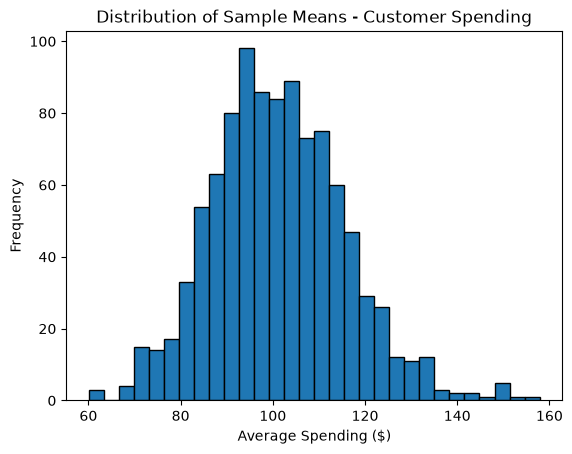

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# This function simulates customer spending data
def generate_customer_spending(num_customers):
    # Simulate a non-normal distribution of spending (e.g., exponential, skewed, etc.)
    return np.random.exponential(100, num_customers)  # Change parameters as needed

# Function to calculate sample means
def calculate_sample_means(data, sample_size, num_samples):
    sample_means = []
    for _ in range(num_samples):
        sample = np.random.choice(data, sample_size)
        sample_means.append(np.mean(sample))
    return sample_means

# Parameters for simulation
num_customers = 1000  # Total number of customer data points
sample_size = 50      # Size of each sample
num_samples = 1000    # Number of samples to take

# Generate customer spending data
customer_spending = generate_customer_spending(num_customers)

# Calculate sample means
sample_means = calculate_sample_means(customer_spending, sample_size, num_samples)

# Plot the distribution of sample means
plt.hist(sample_means, bins=30, edgecolor='black')
plt.xlabel('Average Spending ($)')
plt.ylabel('Frequency')
plt.title('Distribution of Sample Means - Customer Spending')
plt.show()

## Solutions

**1st-class fares vs 85 USD**

In [25]:
c1_sample = data[data['Pclass'] == 1]['Fare'].sample(30, random_state=42)
st.ttest_1samp(c1_sample, 85)

TtestResult(statistic=np.float64(-0.6793103452320937), pvalue=np.float64(0.5023276014035132), df=np.int64(29))

**Soft drinks, 180 / 210 / 210**

In [26]:
O = np.array([180, 210, 210])
E = np.array([240, 180, 180])

print(st.chisquare(f_obs=O, f_exp=E))
st.chi2.sf((np.square(O - E) / E).sum(), 2)

Power_divergenceResult(statistic=np.float64(25.0), pvalue=np.float64(3.7266531720786718e-06))


np.float64(3.7266531720786718e-06)